# PaleographIA — Notebook comparativo: modelo base × modelos ajustados

**Projeto Integrador IV** — Caio Augusto de Souza Soares, Guilherme Rodrigues Veiga, Rodolfo Vinicius
Cima Takemoto e Tiago Galhardo Avelar.

**Problema.** Ler manuscritos dos séculos XVII a XIX do Arquivo Histórico de Jundiaí exige tempo e
formação paleográfica. O PaleographIA sugere a leitura de cada linha para que um humano confira e
valide.

**O que este notebook compara.** Quatro reconhecedores de linha leem os mesmos recortes:

| Papel | Modelo | Treino |
| --- | --- | --- |
| **Baseline** | PP-OCRv6 medium, sem ajuste | Pré-treino multilíngue público (Kiessling, 2026) |
| Ajustado A | PP-OCRv6 + ajuste fino | 191 linhas do Traslado do Auto de Criação da Vila (Jundiaí) |
| Ajustado B | PP-OCRv6 + ajuste fino | As mesmas 191 linhas + 550 linhas públicas da Inquisição |
| Ajustado D1 | PP-OCRv6 + ajuste fino | As mesmas 191 linhas + 63 linhas das Posturas de 1831 validadas pela equipe; é o modelo da aplicação (incluído em 12/11) |

**Dados do próprio projeto.**
- **Validação** (desenvolvimento): 7 linhas da sessão da Câmara de 25/06/1795, de outra mão; usada para
  escolher o checkpoint.
- **Teste reservado** (avaliação final): 49 linhas de duas mãos que nenhum modelo viu, um pagamento de
  1759 e um contrato de 1763. Os integrantes transcreveram as linhas às cegas, com o reconhecedor
  desligado. A referência foi congelada com hashes antes da avaliação, e **cada modelo rodou uma única
  vez** nela.

**Métricas.** CER (erro de caracteres) e WER (erro de palavras): distância de edição entre a leitura e
a referência, dividida pelo tamanho da referência, em Unicode NFC, com espaços simplificados e
preservando caixa, acentos e grafia.

**Requisitos de reprodutibilidade.** Python 3.10 ou mais novo, `jiwer` e `matplotlib`. O notebook roda
sobre as leituras já gravadas no repositório público: não precisa de GPU, de Docker nem das imagens.
No Colab, ele clona o repositório sozinho. Para gerar as leituras de novo, use os scripts
`scripts/avaliar_validacao.py` e `scripts/avaliar_teste_final.py`, com a imagem Docker
`paleographia-kraken:7.1.0-cpu`. O segundo se recusa a rodar outra vez no teste, por protocolo.


In [1]:
# Localiza o repositório (local) ou baixa o código público (Colab).
import json, os, random, subprocess, sys
from pathlib import Path

raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/paleographia/pln_erros.py").exists()), None)
if raiz is None:  # Colab ou pasta solta
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/aj1no/paleographia-htr.git"], check=True)
    raiz = Path("paleographia-htr").resolve()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "jiwer"], check=True)
sys.path.insert(0, str(raiz / "src"))
os.chdir(raiz)

import hashlib, unicodedata
import jiwer
import matplotlib.pyplot as plt
from paleographia.pln_erros import analisar, TIPOS

VALIDACAO = raiz / "docs/experimentos/ppocrv6_ajuste_fino_20261105/dados/avaliacao_validacao_base_A_B_nfc.json"
TESTE = raiz / "docs/revisao_humana/teste_reservado_congelado_20261109"
VALIDACAO_D1 = raiz / "docs/experimentos/ppocrv6_ajustado_C/dados/avaliacao_validacao_D1_1795_nfc.json"
print("Repositório:", raiz.name)

Repositório: PaleographIA


## 1. Carregar as leituras e conferir a integridade

Na validação, os nomes dos arquivos de pesos viram os nomes curtos dos modelos. No teste, o notebook
confere se a referência é a mesma que foi congelada (SHA-256) antes de usar qualquer número.

In [2]:
NOMES = {"medium.safetensors": "Base", "medium_ajustado_A_gravado.safetensors": "Ajustado A",
         "medium_ajustado_B_gravado.safetensors": "Ajustado B", "medium_ajustado_D1.safetensors": "Ajustado D1"}
val_bruto = json.loads(VALIDACAO.read_text(encoding="utf-8"))
val_bruto.update(json.loads(VALIDACAO_D1.read_text(encoding="utf-8")))
validacao = {NOMES[Path(k).name]: v["rows"] for k, v in val_bruto.items()}

congelamento = json.loads((TESTE / "congelamento.json").read_text(encoding="utf-8"))
hash_ref = hashlib.sha256((TESTE / "referencia.jsonl").read_bytes()).hexdigest()
assert hash_ref == congelamento["reference_sha256"], "referência diferente da congelada"
teste_bruto = json.loads((TESTE / "avaliacao_final.json").read_text(encoding="utf-8"))
assert teste_bruto["reference_sha256"] == hash_ref
teste = {k.replace("PP-OCRv6 base", "Base").replace("PP-OCRv6 ajustado ", "Ajustado "): v["rows"]
         for k, v in teste_bruto["models"].items()}
DOCS = {"pagamento_thomas_pardo": "Pagamento (1759)", "contrato_livro12_1763": "Contrato (1763)"}
MODELOS = ["Base", "Ajustado A", "Ajustado B", "Ajustado D1"]

print("Validação:", len(validacao["Base"]), "linhas |",
      "Teste:", len(teste["Base"]), "linhas, congelado em", congelamento["frozen_at"][:10],
      "| referência", hash_ref[:12], "conferida")
for doc, nome in DOCS.items():
    print(f"  {nome}: {sum(r['document_id'] == doc for r in teste['Base'])} linhas")

Validação: 7 linhas | Teste: 49 linhas, congelado em 2026-11-09 | referência 2d0fb78e021f conferida
  Pagamento (1759): 14 linhas
  Contrato (1763): 35 linhas


## 2. CER e WER: baseline × ajustados

A função abaixo recalcula as métricas a partir das leituras e confere que bate com o valor gravado na
avaliação.

In [3]:
def nfc(t):
    return " ".join(unicodedata.normalize("NFC", t or "").split())

def metricas(linhas):
    refs, hyps = [nfc(l["ref"]) for l in linhas], [nfc(l["hyp"]) for l in linhas]
    return jiwer.cer(refs, hyps), jiwer.wer(refs, hyps)

conjuntos = {"Validação 1795 (7)": validacao,
             "Teste: total (49)": teste,
             "Teste: pagamento (14)": {m: [l for l in teste[m] if l["document_id"] == "pagamento_thomas_pardo"] for m in MODELOS},
             "Teste: contrato (35)": {m: [l for l in teste[m] if l["document_id"] == "contrato_livro12_1763"] for m in MODELOS}}
tabela = {c: {m: metricas(d[m]) for m in MODELOS} for c, d in conjuntos.items()}

for m in MODELOS:  # confere com o que a avaliação gravou
    gravado = teste_bruto["models"][{"Base": "PP-OCRv6 base"}.get(m, "PP-OCRv6 a" + m[1:])]["total"]
    assert round(tabela["Teste: total (49)"][m][0], 4) == gravado["cer"]

print(f"{'Conjunto':24s}" + "".join(f"{m:>18s}" for m in MODELOS))
for c, linha in tabela.items():
    print(f"{c:24s}" + "".join(f"{f'{cer:.1%} / {wer:.1%}':>18s}" for cer, wer in linha.values()))
print("\n(cada célula: CER / WER; menor é melhor)")

Conjunto                              Base        Ajustado A        Ajustado B       Ajustado D1
Validação 1795 (7)           14.2% / 56.7%     10.7% / 41.8%     10.1% / 38.8%      9.9% / 38.8%
Teste: total (49)            64.0% / 95.3%     60.5% / 93.7%     60.9% / 94.4%     55.4% / 94.4%
Teste: pagamento (14)        31.1% / 79.5%     27.9% / 78.3%     28.3% / 77.1%     29.0% / 78.3%
Teste: contrato (35)        77.1% / 101.4%     73.5% / 99.5%    73.8% / 100.9%    65.9% / 100.5%

(cada célula: CER / WER; menor é melhor)


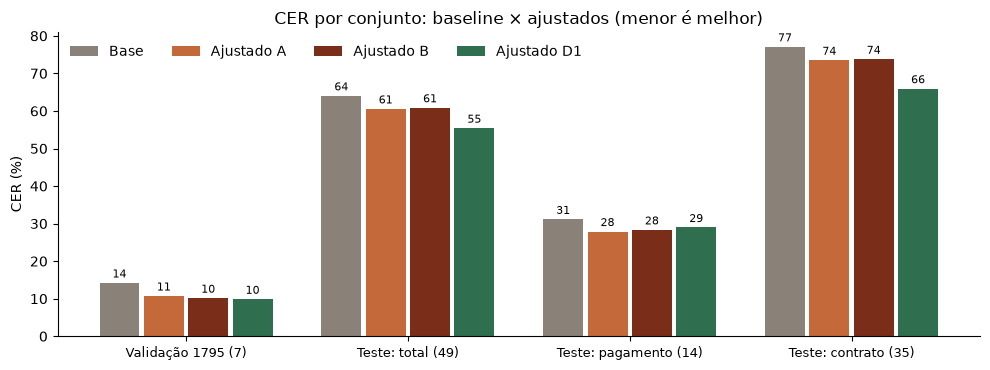

In [4]:
cores = {"Base": "#8a8178", "Ajustado A": "#c46a3a", "Ajustado B": "#7a2e1a", "Ajustado D1": "#2f6f4f"}
fig, eixo = plt.subplots(figsize=(10, 3.8))
largura = 0.2
for i, m in enumerate(MODELOS):
    xs = [j + (i - 1.5) * largura for j in range(len(tabela))]
    ys = [tabela[c][m][0] * 100 for c in tabela]
    barras = eixo.bar(xs, ys, largura - 0.02, color=cores[m], label=m)
    eixo.bar_label(barras, labels=[f"{y:.0f}" for y in ys], padding=2, fontsize=8)
eixo.set_xticks(range(len(tabela)), list(tabela), fontsize=9)
eixo.set_ylabel("CER (%)")
eixo.set_title("CER por conjunto: baseline × ajustados (menor é melhor)")
eixo.spines[["top", "right"]].set_visible(False)
eixo.legend(frameon=False, ncol=4, loc="upper left")
plt.tight_layout(); plt.show()

## 3. A diferença é real? Intervalos de confiança e comparação pareada

Com poucas linhas, uma linha a mais ou a menos muda o resultado. O bootstrap sorteia as linhas com
reposição 2.000 vezes e mostra a faixa de 95% do CER. A **comparação pareada** usa as mesmas linhas
sorteadas para o baseline e para o ajustado. Se a faixa da diferença fica toda abaixo de zero, o
ajustado é melhor de forma consistente.

In [5]:
def cer(linhas):
    return metricas(linhas)[0]

def faixa(valores):
    v = sorted(valores); n = len(v)
    return v[int(0.025 * n)], v[int(0.975 * n) - 1]

def bootstrap(linhas, funcao, n=2000, semente=7):
    rnd = random.Random(semente)
    return faixa([funcao([linhas[rnd.randrange(len(linhas))] for _ in linhas]) for _ in range(n)])

for nome_conjunto, dados in [("Validação 1795", validacao), ("Teste reservado", teste)]:
    print(nome_conjunto)
    base = dados["Base"]
    for m in MODELOS:
        baixo, alto = bootstrap(dados[m], cer)
        texto = f"  {m:11s} CER {cer(dados[m]):6.1%}  IC95% {baixo:6.1%} a {alto:6.1%}"
        if m != "Base":
            pares = list(zip(dados[m], base))
            d_baixo, d_alto = bootstrap(pares, lambda s: cer([a for a, _ in s]) - cer([b for _, b in s]))
            texto += f" | diferença para o baseline: {d_baixo * 100:+.1f} a {d_alto * 100:+.1f} pontos"
        print(texto)
    pares = list(zip(dados["Ajustado D1"], dados["Ajustado B"]))
    d_baixo, d_alto = bootstrap(pares, lambda s: cer([a for a, _ in s]) - cer([b for _, b in s]))
    print(f"  D1 contra B: {(cer(dados['Ajustado D1']) - cer(dados['Ajustado B'])) * 100:+.1f} pontos, IC95% {d_baixo * 100:+.1f} a {d_alto * 100:+.1f}")

Validação 1795


  Base        CER  14.2%  IC95%  12.0% a  16.2%


  Ajustado A  CER  10.7%  IC95%   8.5% a  13.5% | diferença para o baseline: -6.2 a -0.6 pontos


  Ajustado B  CER  10.1%  IC95%   7.1% a  13.6% | diferença para o baseline: -7.0 a -1.4 pontos


  Ajustado D1 CER   9.9%  IC95%   7.0% a  13.2% | diferença para o baseline: -7.5 a -1.2 pontos


  D1 contra B: -0.3 pontos, IC95% -2.8 a +2.1
Teste reservado


  Base        CER  64.0%  IC95%  57.1% a  71.4%


  Ajustado A  CER  60.5%  IC95%  53.5% a  67.8% | diferença para o baseline: -5.6 a -1.5 pontos


  Ajustado B  CER  60.9%  IC95%  54.0% a  68.0% | diferença para o baseline: -4.9 a -1.4 pontos


  Ajustado D1 CER  55.4%  IC95%  49.5% a  61.9% | diferença para o baseline: -11.7 a -5.7 pontos


  D1 contra B: -5.4 pontos, IC95% -8.0 a -3.2


## 4. Linha a linha: quantas linhas o ajuste melhorou?

In [6]:
for nome_conjunto, dados in [("Validação 1795", validacao), ("Teste reservado", teste)]:
    for m in ["Ajustado A", "Ajustado B", "Ajustado D1"]:
        melhor = sum(a["cer"] < b["cer"] for a, b in zip(dados[m], dados["Base"]))
        pior = sum(a["cer"] > b["cer"] for a, b in zip(dados[m], dados["Base"]))
        igual = len(dados[m]) - melhor - pior
        print(f"{nome_conjunto:16s} {m}: melhorou {melhor}, piorou {pior}, igual {igual} (de {len(dados[m])})")

vazias = sum(not l["hyp"] for l in teste["Ajustado B"])
print(f"\nNo teste, {vazias} linhas ficaram sem nenhuma leitura em todos os modelos:",
      sorted({l["ref"] for l in teste["Ajustado B"] if not l["hyp"]}))

Validação 1795   Ajustado A: melhorou 5, piorou 1, igual 1 (de 7)
Validação 1795   Ajustado B: melhorou 4, piorou 0, igual 3 (de 7)
Validação 1795   Ajustado D1: melhorou 4, piorou 0, igual 3 (de 7)
Teste reservado  Ajustado A: melhorou 23, piorou 9, igual 17 (de 49)
Teste reservado  Ajustado B: melhorou 23, piorou 7, igual 19 (de 49)
Teste reservado  Ajustado D1: melhorou 28, piorou 3, igual 18 (de 49)

No teste, 9 linhas ficaram sem nenhuma leitura em todos os modelos: [',', 'Com', 'de ne', 'de o', 'na', 'não e possivele ler', 'os', 'ou', 'so']


In [7]:
print("Exemplos do pagamento (teste), referência humana × baseline × ajustado B\n")
pagamento = [(r, b, a) for r, b, a in zip(teste["Base"], teste["Base"], teste["Ajustado B"])
             if r["document_id"] == "pagamento_thomas_pardo"]
for r, b, a in pagamento[6:9] + pagamento[10:12]:
    print("Referência:", r["ref"])
    print(f"Baseline:   {b['hyp']}   (CER {b['cer']:.0%})")
    print(f"Ajustado B: {a['hyp']}   (CER {a['cer']:.0%})\n")

Exemplos do pagamento (teste), referência humana × baseline × ajustado B

Referência: Mandado para o procurador
Baseline:   Landado parao Procurador   (CER 12%)
Ajustado B: Landado parao Procurador   (CER 12%)

Referência: do conselho Nicolal Guedes
Baseline:   do Concelho NicoLaõ Geuedes sin   (CER 35%)
Ajustado B: do Concelho NNicolaõ Guedes Fin   (CER 31%)

Referência: Nosso mandado sendo primeiro
Baseline:   oho mandado sendostrimeyro   (CER 21%)
Ajustado B: oho mandado sendostrimeyro   (CER 21%)

Referência: mento e na forma dele satisfa
Baseline:   ento e na forma delle sateffa   (CER 14%)
Ajustado B: nento e na forma delle satiffa   (CER 10%)

Referência: ca pelos reditos da câmara a Thomas
Baseline:   eapellos Redetos da Camara a Romas.   (CER 29%)
Ajustado B: eapellos Redetos da Camara a Romas   (CER 26%)



## 5. Que tipo de erro sobra?

Cada linha é alinhada à referência por distância de edição, e cada erro recebe um tipo linguístico. É
a mesma classificação do Notebook 3 de PLN (`src/paleographia/pln_erros.py`). A tabela mostra quantos
pontos de CER cada tipo representa no pagamento, a parte do teste em que o modelo já lê a maior parte
das letras.

In [8]:
pagamento_por_modelo = {m: [l for l in teste[m] if l["document_id"] == "pagamento_thomas_pardo"] for m in MODELOS}
analises = {m: analisar([(l["ref"], l["hyp"]) for l in pagamento_por_modelo[m]]) for m in ["Base", "Ajustado B"]}
print(f"{'Tipo de erro':40s}{'Baseline':>10s}{'Ajustado B':>12s}   (pontos de CER)")
for t in TIPOS:
    print(f"{t:40s}" + "".join(f"{analises[m]['por_tipo'][t]['pontos_de_cer']:>11.1%}" for m in analises))
print(f"{'Total':40s}" + "".join(f"{analises[m]['cer']:>11.1%}" for m in analises))

Tipo de erro                              Baseline  Ajustado B   (pontos de CER)
espaço (palavras coladas ou separadas)         4.1%       4.1%
pontuação                                      0.9%       0.6%
abreviatura                                    0.0%       0.0%
maiúscula/minúscula                            1.5%       1.5%
acento ou til                                  0.4%       0.6%
grafia histórica                               2.4%       2.1%
nome próprio                                   4.5%       4.3%
forma da letra                                17.4%      15.0%
Total                                         31.1%      28.3%


## 6. Conclusão

- **O ajuste fino melhora o baseline.** Na validação, o CER cai de 14,2% para 10,7% (A) e 10,1% (B).
  No teste reservado, cai de 64,0% para 60,5% e 60,9%. A diferença pareada fica toda abaixo de zero,
  então a melhora é consistente, e não sorte de uma ou duas linhas.
- **A e B não se distinguem.** Somar 550 linhas da Inquisição não trouxe ganho mensurável.
- **O D1 passa o B (incluído em 12/11).** Somar 63 linhas das Posturas de 1831, do próprio acervo,
  baixou o teste para 55,4%. A diferença pareada para o B fica toda abaixo de zero e vem do contrato
  (74% → 66%); no pagamento, os dois empatam, e o WER não muda. O D1 foi escolhido antes, num fólio
  das Posturas fora do treino, e rodou no teste uma única vez, em 11/11.
- **A generalização ainda é o limite.** O erro sobe muito fora da validação: cerca de 28% no
  pagamento, de letra grande e regular, e cerca de 74% no contrato, de escrita densa e com a tinta do
  verso aparecendo (66% com o D1). O modelo aprende as mãos que viu, e não "o português do século
  XVIII".
- **Próximo passo objetivo:** rotular mais documentos de mãos diferentes para o treino, com dupla
  leitura às cegas nas referências. O modelo continua sendo uma sugestão: quem valida é o humano.

**Limitações.** A validação tem 7 linhas e foi usada para escolher o checkpoint de A e B (o D1 usou
também as 31 linhas do fólio 101r das Posturas). O teste já foi usado por quatro modelos, uma vez
cada, então a comparação entre eles não é mais totalmente cega. O teste tem 49
linhas de duas mãos, e cada documento foi lido por um só integrante. Na referência do contrato, foram
notados problemas só depois do resultado: uma nota do revisor validada como texto e algumas linhas
na grafia da edição. Pelo protocolo, a referência congelada não foi alterada.

---
Comentários:
Ferramenta: Claude Code (Claude Opus 5.5 e, na inclusão do D1 em 12/11, Claude Fable 5.2, Anthropic)
Utilização: Utilizado para desenvolvimento do código deste notebook, do pipeline de avaliação e do
congelamento do teste, e para redação dos textos explicativos, revisados pela equipe. A transcrição
das referências (validação e teste) foi feita por integrantes da equipe, sem IA.
---